# 03 · Entrenamiento y evaluación


**Objetivo del proyecto:**
Desarrollar un modelo de Machine Learning capaz de identificar las señales de deterioro de los discos de almacenamiento de un centro de datos y estimar la probabilidad de que fallen en los próximos 30 días, permitiendo actuar antes de que suceda.

## Comprensión del problema y elección de la métrica

*El punto de partida es facilitar al equipo de operaciones de un centro de datos saber qué discos tienen una probabilidad alta de fallar pronto, para cambiarlos antes de que provoquen una avería. Target: ¿falla el disco en los próximos 30 días?*

*La respuesta es una categoría con dos valores (1 = falla, 0 = no falla): es un problema de **clasificación binaria**.*

*El error más costoso es el **falso negativo**: que el modelo diga «sano» y el disco falle. Provoca una avería por sorpresa y puede detener el servicio (una caída grave cuesta más de 100.000 $, según el Uptime Institute 2026). El **falso positivo** (revisar un disco que estaba sano) es más barato.*

*Por eso la métrica principal es el **recall de la clase 1** (de todos los discos que fallan, cuántos se detectan). Se tiene en cuenta también la **precisión** (de todas las alarmas, cuántas son reales) para no saturar al equipo con falsas alarmas.*

*Las clases no estarán equilibradas: en una flota real falla en torno al 1-2 % de los discos al año. Por eso:*
- *la **accuracy no sirve** (decir siempre «sano» acertaría casi siempre sin detectar ningún fallo);*
- *para comparar modelos se usa **PR-AUC** (`average_precision`), que resume precisión y recall sin depender del umbral y es la recomendada cuando la clase positiva es rara (documentación de scikit-learn, 3.4 Metrics and scoring).*

*La predicción se traducirá en dos acciones con costes distintos: **vigilar** un disco (revisarlo y comprobar las copias) es barato, así que ahí prima detectar muchos fallos (recall); **sustituirlo** cuesta dinero, así que ahí prima que la alarma sea real (precisión). Por eso el modelo dará una probabilidad y se elegirán **dos umbrales** con validación cruzada, nunca con el test.*

## Imports y datos de entrenamiento

*Leo train y test tal como los dejé en el notebook 02, y las listas de variables desde el JSON. Además de X e y guardo los grupos: el número de serie de cada fila. Se los paso a toda la validación cruzada para que un mismo disco no caiga en dos pliegues; si lo hiciera, el modelo se examinaría con discos que ya conoce.*

In [1]:
import os
import json
import pickle

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import FunctionTransformer, StandardScaler, OneHotEncoder
from sklearn.model_selection import StratifiedGroupKFold, cross_validate, cross_val_predict, GridSearchCV, learning_curve
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import (classification_report, confusion_matrix, ConfusionMatrixDisplay, recall_score,
                             precision_score, average_precision_score, silhouette_score, PrecisionRecallDisplay)
from sklearn.inspection import permutation_importance
from scipy.stats import ttest_rel
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE
from imblearn.under_sampling import RandomUnderSampler
from lightgbm import LGBMClassifier
from xgboost import XGBClassifier
from catboost import CatBoostClassifier

if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")

target = "falla_30d"
train_set = pd.read_csv("data/train/train.csv", low_memory = False)
test_set = pd.read_csv("data/test/test.csv", low_memory = False)
with open("data/processed/conjuntos_variables.json") as f:
    info = json.load(f)
conjuntos = info["conjuntos"]
features_cat = info["categoricas"]
reducido = conjuntos["reducido"]

X_train = train_set[reducido + features_cat]
y_train = train_set[target]
X_test = test_set[reducido + features_cat]
y_test = test_set[target]
grupos = train_set["serial_number"]          # para que un mismo disco no caiga en dos pliegues
print("X_train:", X_train.shape, "| X_test:", X_test.shape, "| discos en train:", grupos.nunique())

X_train: (20760, 17) | X_test: (5163, 17) | discos en train: 18671


## Preprocesado dentro de un pipeline

*Relleno los huecos con la mediana, aplico log(1 + x) a las variables muy asimétricas y escalo solo para los modelos que lo necesitan (regresión logística, KNN, SVM). El fabricante y el datacenter pasan a One-Hot. Lo meto todo en un pipeline para que, en cada pliegue, la mediana y el escalado se calculen solo con la parte de entrenamiento.*

In [2]:
asimetria = train_set[conjuntos["todas"]].skew()
asimetricas_todas = list(asimetria[asimetria > 1].index)
print("Numéricas muy asimétricas (skew > 1):", len(asimetricas_todas), "de", len(conjuntos["todas"]))

def crear_preprocesado(lista_num, escalar):
    asimetricas = [c for c in lista_num if c in asimetricas_todas]
    resto = [c for c in lista_num if c not in asimetricas_todas]
    pasos_asim = [("imputar", SimpleImputer(strategy = "median")),
                  ("log", FunctionTransformer(np.log1p, feature_names_out = "one-to-one"))]
    pasos_resto = [("imputar", SimpleImputer(strategy = "median"))]
    if escalar:
        pasos_asim.append(("escalar", StandardScaler()))
        pasos_resto.append(("escalar", StandardScaler()))
    return ColumnTransformer([("num_asimetricas", Pipeline(pasos_asim), asimetricas),
                              ("num_resto", Pipeline(pasos_resto), resto),
                              ("cat", OneHotEncoder(handle_unknown = "ignore"), features_cat)])

crear_preprocesado(reducido, escalar = True)

Numéricas muy asimétricas (skew > 1): 41 de 46


,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num_asimetricas', ...), ('num_resto', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name

## Baseline: lo que hay que superar

*Antes de entrenar nada, miro dos referencias. Una es no hacer nada: decir siempre "sano". La otra es la regla que usaría un técnico: avisar si el disco tiene algún sector dañado. Si el modelo no mejora a esta última, no merece la pena.*

In [3]:
regla = ((train_set[["smart_5_raw", "smart_197_raw", "smart_198_raw"]].fillna(0) > 0).any(axis = 1)).astype(int)
print("Regla «algún sector dañado > 0» | recall:", round(recall_score(y_train, regla), 3),
      "| precisión:", round(precision_score(y_train, regla), 3))
print("Siempre «sano» | recall: 0.0 | accuracy:", round(1 - y_train.mean(), 3))

Regla «algún sector dañado > 0» | recall: 0.659 | precisión: 0.568
Siempre «sano» | recall: 0.0 | accuracy: 0.894


*Decir siempre "sano" acierta el 89 % y no detecta ni un fallo: por eso la accuracy no sirve aquí. La regla del técnico detecta el 66 % de los fallos, pero solo el 57 % de sus avisos son reales. Esa es la marca que el modelo tiene que superar.*

## Modelos y validación cruzada agrupada por disco

*Pruebo ocho modelos supervisados, de los más sencillos a los de boosting. Todos tienen en cuenta que solo falla el 11 %: les doy más peso a los fallos (class_weight o su equivalente).*

*Para validar uso StratifiedGroupKFold con 5 pliegues. Cada pliegue mantiene el mismo porcentaje de fallos y nunca reparte las filas de un mismo disco entre dos pliegues. Mido recall, precisión y, sobre todo, PR-AUC, que resume cómo de bien ordena el modelo los discos de más a menos riesgo.*

In [4]:
peso_positivos = (y_train == 0).sum() / (y_train == 1).sum()
modelos = {
    "Regresion Logistica L1": (LogisticRegression(l1_ratio = 1, solver = "liblinear", class_weight = "balanced", max_iter = 1000, random_state = 42), True),
    "KNN": (KNeighborsClassifier(n_neighbors = 15), True),
    "SVM": (SVC(class_weight = "balanced", random_state = 42), True),
    "Arbol de decision": (DecisionTreeClassifier(max_depth = 6, class_weight = "balanced", random_state = 42), False),
    "Random Forest": (RandomForestClassifier(max_depth = 10, class_weight = "balanced", n_jobs = 1, random_state = 42), False),
    "XGBoost": (XGBClassifier(max_depth = 6, scale_pos_weight = peso_positivos, n_jobs = 1, random_state = 42, verbosity = 0), False),
    "LightGBM": (LGBMClassifier(max_depth = 6, class_weight = "balanced", n_jobs = 1, random_state = 42, verbose = -1), False),
    "CatBoost": (CatBoostClassifier(depth = 6, auto_class_weights = "Balanced", thread_count = 1, random_state = 42, verbose = 0, allow_writing_files = False), False),
}
# el booleano indica si el modelo necesita escalar (distancias, penalización o varianza)

def crear_pipeline(nombre, lista_num):
    modelo, escalar = modelos[nombre]
    return Pipeline([("preprocesado", crear_preprocesado(lista_num, escalar)), ("modelo", clone(modelo))])

cv = StratifiedGroupKFold(n_splits = 5, shuffle = True, random_state = 42)
scoring = {"recall": "recall", "precision": "precision", "pr_auc": "average_precision"}

## Comparativa de modelos

*Comparo los ocho modelos y un noveno no supervisado + supervisado (PCA a 10 componentes y después Random Forest). Todos con los mismos pliegues y la misma métrica, para que la comparación sea justa.*

,modelo,recall,precision,pr_auc,pr_auc_std
6,LightGBM,0.711,0.582,0.706,0.037
4,Random Forest,0.704,0.643,0.704,0.035
7,CatBoost,0.694,0.581,0.696,0.039
8,PCA + Random Forest,0.689,0.626,0.693,0.033
0,Regresion Logistica L1,0.707,0.511,0.676,0.045
5,XGBoost,0.615,0.584,0.657,0.039
1,KNN,0.522,0.798,0.643,0.038
3,Arbol de decision,0.704,0.537,0.630,0.041
2,SVM,0.729,0.584,0.545,0.030


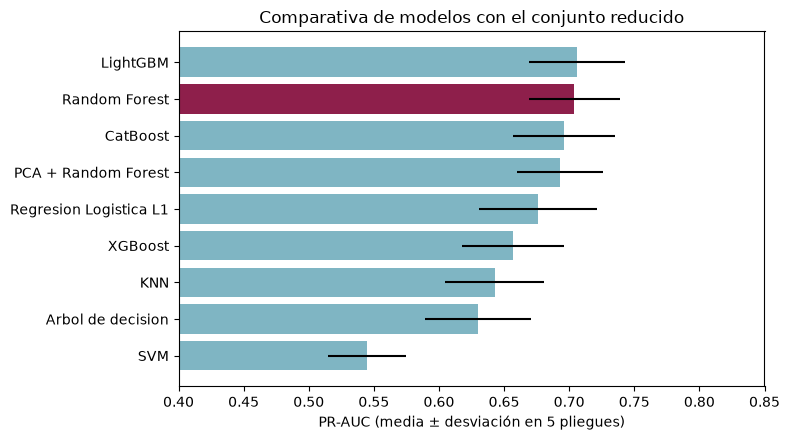

In [5]:
resultados = []
for nombre in modelos:
    cv_res = cross_validate(crear_pipeline(nombre, reducido), X_train, y_train, cv = cv, scoring = scoring, groups = grupos, n_jobs = -1)
    resultados.append([nombre, cv_res["test_recall"].mean(), cv_res["test_precision"].mean(),
                       cv_res["test_pr_auc"].mean(), cv_res["test_pr_auc"].std()])
pca_rf = Pipeline([("preprocesado", crear_preprocesado(reducido, escalar = True)),
                   ("pca", PCA(n_components = 10, random_state = 42)),
                   ("modelo", RandomForestClassifier(max_depth = 10, class_weight = "balanced", random_state = 42))])
cv_res = cross_validate(pca_rf, X_train, y_train, cv = cv, scoring = scoring, groups = grupos, n_jobs = -1)
resultados.append(["PCA + Random Forest", cv_res["test_recall"].mean(), cv_res["test_precision"].mean(),
                   cv_res["test_pr_auc"].mean(), cv_res["test_pr_auc"].std()])

comparativa = pd.DataFrame(resultados, columns = ["modelo", "recall", "precision", "pr_auc", "pr_auc_std"])
comparativa = comparativa.sort_values("pr_auc").round(3)
plt.figure(figsize = (8, 4.5))
plt.barh(comparativa["modelo"], comparativa["pr_auc"], xerr = comparativa["pr_auc_std"],
         color = ["#8E1F4B" if m == "Random Forest" else "#7FB5C3" for m in comparativa["modelo"]])   # ← cambiado
plt.xlim(0.4, 0.85)
plt.xlabel("PR-AUC (media ± desviación en 5 pliegues)")
plt.title("Comparativa de modelos con el conjunto reducido")
plt.tight_layout()
comparativa.sort_values("pr_auc", ascending = False)

*LightGBM (0,706), Random Forest (0,704) y CatBoost (0,696) quedan arriba; la regresión logística, en 0,676. Todos mejoran mucho al azar, que estaría en 0,11 (la proporción de fallos). La desviación entre pliegues (±0,04) es mayor que las diferencias entre los primeros, pero eso no significa que empaten: la desviación mide sobre todo que unos pliegues son más difíciles que otros para todos los modelos a la vez. Para saber si uno gana de verdad, hay que compararlos pliegue a pliegue.*

## Comparación pareada: pliegue a pliegue

*Las barras de error se solapan, pero eso no basta para decir que hay empate. Todos los modelos se han validado con los mismos 5 pliegues, así que comparo cada pliegue por separado y aplico un t-test pareado. Lo hago con los dos candidatos más fuertes (Random Forest y LightGBM) y con la regresión logística, el modelo sencillo de referencia.*

In [6]:
# Mismos 5 pliegues para todos: comparo pliegue a pliegue (comparación pareada)
por_pliegue = {}
for nombre in ["Regresion Logistica L1", "Random Forest", "LightGBM"]:
    cv_res = cross_validate(crear_pipeline(nombre, reducido), X_train, y_train, cv = cv,
                            scoring = "average_precision", groups = grupos, n_jobs = -1)
    por_pliegue[nombre] = cv_res["test_score"]
por_pliegue = pd.DataFrame(por_pliegue, index = ["pliegue " + str(k) for k in range(1, 6)])
por_pliegue["RF - LogReg"] = por_pliegue["Random Forest"] - por_pliegue["Regresion Logistica L1"]
por_pliegue["RF - LightGBM"] = por_pliegue["Random Forest"] - por_pliegue["LightGBM"]
print("t-test pareado RF vs regresión logística: p =", round(ttest_rel(por_pliegue["Random Forest"], por_pliegue["Regresion Logistica L1"]).pvalue, 3))
print("t-test pareado RF vs LightGBM: p =", round(ttest_rel(por_pliegue["Random Forest"], por_pliegue["LightGBM"]).pvalue, 3))
por_pliegue.round(3)

t-test pareado RF vs regresión logística: p = 0.042
t-test pareado RF vs LightGBM: p = 0.307


,Regresion Logistica L1,Random Forest,LightGBM,RF - LogReg,RF - LightGBM
pliegue 1,0.642,0.665,0.669,0.023,-0.004
pliegue 2,0.739,0.734,0.741,-0.005,-0.006
pliegue 3,0.654,0.705,0.701,0.051,0.004
pliegue 4,0.720,0.750,0.756,0.030,-0.006
pliegue 5,0.624,0.663,0.663,0.039,0.001


*Random Forest supera a la regresión logística en 4 de los 5 pliegues, por 0,03 de media, y la diferencia es significativa (p = 0,04). Frente a LightGBM, la diferencia en cada pliegue no pasa de ±0,006 (p = 0,31): empatan. Me quedo con Random Forest. Rinde igual que el mejor, tiene mejor precisión, pocos hiperparámetros que ajustar y es más fácil de explicar que un boosting.*

## ¿Qué conjunto de variables usa el ganador?

*Con Random Forest ya elegido, pruebo los tres conjuntos que preparé en el notebook 02: todas las variables (46), sin las poco útiles (28) y el reducido (15). Si empatan, me quedo con el más pequeño: es más rápido y la app pedirá menos datos.*

In [7]:
ganador = "Random Forest"
res = []
for nombre, lista in conjuntos.items():
    cv_res = cross_validate(crear_pipeline(ganador, lista), train_set[lista + features_cat], y_train,
                            cv = cv, scoring = scoring, groups = grupos, n_jobs = -1)
    res.append([nombre, len(lista), cv_res["test_pr_auc"].mean(), cv_res["test_pr_auc"].std(),
                cv_res["test_recall"].mean(), cv_res["test_precision"].mean()])
tabla_conjuntos = pd.DataFrame(res, columns = ["conjunto", "n_variables", "pr_auc", "pr_auc_std", "recall", "precision"])
# Las diferencias son menores que la desviación entre pliegues: me quedo con el conjunto más sencillo
variables = conjuntos["reducido"]
X_train = train_set[variables + features_cat]
X_test = test_set[variables + features_cat]
tabla_conjuntos.round(3)

,conjunto,n_variables,pr_auc,pr_auc_std,recall,precision
0,todas,46,0.713,0.033,0.713,0.648
1,sin_poco_utiles,28,0.703,0.033,0.709,0.641
2,reducido,15,0.704,0.035,0.704,0.643


*Los tres conjuntos quedan a menos de 0,01 entre sí, muy por debajo de la variación entre pliegues (±0,03): empate. Me quedo con el reducido. Con 15 variables rinde igual que con 46, entrena más rápido y en la app hay que rellenar menos campos.*

## GridSearchCV: ajustar el Random Forest

*Busco la mejor combinación de profundidad, tamaño mínimo de las hojas y pesos de clase. Mido tres métricas a la vez, pero elijo por PR-AUC (refit = "pr_auc"). Guardo también la nota en entrenamiento para vigilar el sobreajuste. Los pesos de clase entran en la rejilla como un hiperparámetro más, así que la propia búsqueda decide si hace falta balancear.*

In [8]:
scoring_grid = {"pr_auc": "average_precision", "recall": "recall", "precision": "precision"}
grid = GridSearchCV(crear_pipeline(ganador, variables),
                    param_grid = {"modelo__n_estimators": [300],
                                  "modelo__max_depth": [12, None],
                                  "modelo__min_samples_leaf": [1, 5, 20],
                                  "modelo__class_weight": [None, "balanced", "balanced_subsample"]},
                    cv = cv, scoring = scoring_grid, refit = "pr_auc", return_train_score = True,
                    n_jobs = -1, verbose = 2)
grid.fit(X_train, y_train, groups = grupos)
print("Mejores parámetros:", grid.best_params_)
print("PR-AUC en validación cruzada:", round(grid.best_score_, 3))

Fitting 5 folds for each of 18 candidates, totalling 90 fits
Mejores parámetros: {'modelo__class_weight': None, 'modelo__max_depth': 12, 'modelo__min_samples_leaf': 5, 'modelo__n_estimators': 300}
PR-AUC en validación cruzada: 0.725


In [9]:
columnas = ["param_modelo__max_depth", "param_modelo__min_samples_leaf", "param_modelo__class_weight",
            "mean_train_pr_auc", "mean_test_pr_auc", "std_test_pr_auc", "mean_test_recall", "mean_test_precision"]
tabla_grid = pd.DataFrame(grid.cv_results_)[columnas]
# None = sin límite / sin pesos. Lo leo de "params" porque pandas convierte None en NaN
for p in ["max_depth", "class_weight"]:
    tabla_grid["param_modelo__" + p] = [str(params["modelo__" + p]) for params in grid.cv_results_["params"]]
tabla_grid.sort_values("mean_test_pr_auc", ascending = False).head(6).round(3)

,param_modelo__max_depth,param_modelo__min_samples_leaf,param_modelo__class_weight,mean_train_pr_auc,mean_test_pr_auc,std_test_pr_auc,mean_test_recall,mean_test_precision
1,12,5,None,0.846,0.725,0.041,0.526,0.822
0,12,1,None,0.889,0.724,0.041,0.516,0.826
2,12,20,None,0.793,0.721,0.039,0.518,0.817
5,None,20,None,0.816,0.719,0.039,0.521,0.817
4,None,5,None,0.917,0.718,0.042,0.537,0.814
8,12,20,balanced,0.796,0.715,0.036,0.736,0.576


*Gana max_depth = 12, min_samples_leaf = 5 y sin pesos de clase, con una PR-AUC de 0,725. En entrenamiento saca 0,85 y en validación 0,73: hay algo de sobreajuste, pero controlado. Sin límite de profundidad, el entrenamiento sube a 0,92 y la validación no mejora. Sin pesos de clase, con el umbral por defecto (0,5) solo detecta el 53 % de los fallos, pero eso lo arreglo más adelante eligiendo el umbral.*

## Desbalanceo: ¿hace falta tratarlo?

*Solo falla el 11 %, así que comparo cuatro opciones con el Random Forest ya ajustado: no hacer nada, dar más peso a los fallos (class_weight), crear fallos sintéticos (SMOTE) y quitar sanos (undersampling). SMOTE y undersampling van dentro del pipeline de imblearn, para que solo toquen la parte de entrenamiento de cada pliegue y nunca la de validación.*

In [10]:
mejores = grid.best_estimator_.named_steps["modelo"].get_params()
def bosque(class_weight):
    return RandomForestClassifier(n_estimators = 300, max_depth = mejores["max_depth"], min_samples_leaf = mejores["min_samples_leaf"],
                                  class_weight = class_weight, n_jobs = 1, random_state = 42)

prepro = crear_preprocesado(variables, escalar = False)
tecnicas = {"Sin tratar": Pipeline([("preprocesado", prepro), ("modelo", bosque(None))]),
            "class_weight balanced": Pipeline([("preprocesado", prepro), ("modelo", bosque("balanced"))]),
            "SMOTE": ImbPipeline([("preprocesado", prepro), ("smote", SMOTE(random_state = 42)), ("modelo", bosque(None))]),
            "RandomUnderSampler": ImbPipeline([("preprocesado", prepro), ("under", RandomUnderSampler(random_state = 42)), ("modelo", bosque(None))])}
res = []
for nombre, pipe in tecnicas.items():
    cv_res = cross_validate(pipe, X_train, y_train, cv = cv, scoring = scoring, groups = grupos, n_jobs = -1)
    res.append([nombre, cv_res["test_recall"].mean(), cv_res["test_precision"].mean(), cv_res["test_pr_auc"].mean()])
pd.DataFrame(res, columns = ["tecnica", "recall", "precision", "pr_auc"]).round(3)

,tecnica,recall,precision,pr_auc
0,Sin tratar,0.526,0.822,0.725
1,class_weight balanced,0.719,0.628,0.713
2,SMOTE,0.666,0.694,0.704
3,RandomUnderSampler,0.742,0.560,0.705


*Las tres técnicas suben el recall con el umbral por defecto (0,5), pero las tres bajan la PR-AUC: ordenan peor los discos de más a menos riesgo. La mejor PR-AUC sale sin tocar las clases. Por eso no balanceo los datos: trato el desbalanceo moviendo el umbral de decisión, que consigue el recall que necesito sin estropear el orden.*

## Curva de aprendizaje: ¿hacían falta más filas?

*Entreno el modelo final con el 20, 40, 60, 80 y 100 % de train y miro cómo cambia la PR-AUC en validación. Si la curva ya fuera plana, más filas no habrían servido de nada; si sigue subiendo, usar unas 26.000 filas en lugar de 5.000 estaba justificado.*

,filas,pr_auc_validacion,desviacion
0,3321,0.692,0.037
1,6642,0.713,0.045
2,9964,0.719,0.042
3,13285,0.723,0.041
4,16607,0.726,0.041


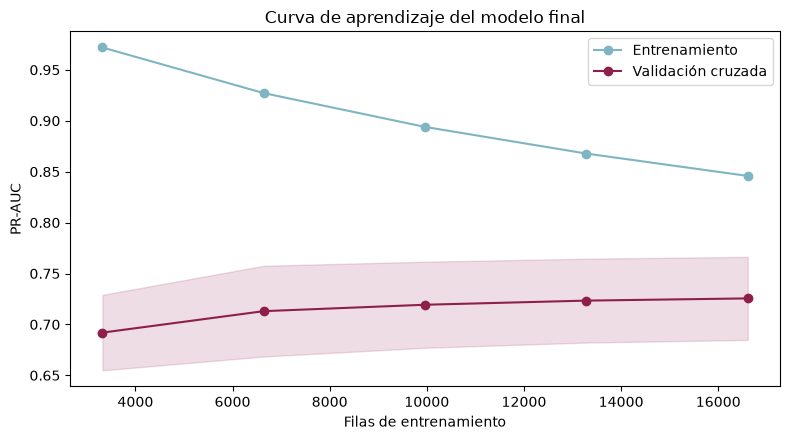

In [11]:
tamanos, train_sc, val_sc = learning_curve(grid.best_estimator_, X_train, y_train, groups = grupos, cv = cv,
                                           scoring = "average_precision", train_sizes = [0.2, 0.4, 0.6, 0.8, 1.0], n_jobs = -1)
plt.figure(figsize = (8, 4.5))
plt.plot(tamanos, train_sc.mean(axis = 1), marker = "o", color = "#7FB5C3", label = "Entrenamiento")
plt.plot(tamanos, val_sc.mean(axis = 1), marker = "o", color = "#8E1F4B", label = "Validación cruzada")
plt.fill_between(tamanos, val_sc.mean(axis = 1) - val_sc.std(axis = 1), val_sc.mean(axis = 1) + val_sc.std(axis = 1), color = "#8E1F4B", alpha = 0.15)
plt.xlabel("Filas de entrenamiento")
plt.ylabel("PR-AUC")
plt.title("Curva de aprendizaje del modelo final")
plt.legend()
plt.tight_layout()
pd.DataFrame({"filas": tamanos, "pr_auc_validacion": val_sc.mean(axis = 1).round(3), "desviacion": val_sc.std(axis = 1).round(3)})

*La validación sube hasta el final: de 0,692 con 3.300 filas a 0,726 con 16.600. Más filas sí ayudan a este modelo, y es el argumento para haber usado unas 26.000 en lugar de 5.000. La subida ya es suave al final, así que añadir muchas más filas daría poco. Las dos líneas se van acercando: con más datos, el modelo memoriza menos y generaliza mejor.*

## No supervisado (I): PCA

*Reduzco las 15 variables con PCA para ver cuántas componentes hacen falta y si, sin saber quién falla, los datos ya muestran alguna separación. El PCA no ve el target: el color lo pongo yo después, solo para mirar.*

Componentes para el 90 % de la varianza: 11


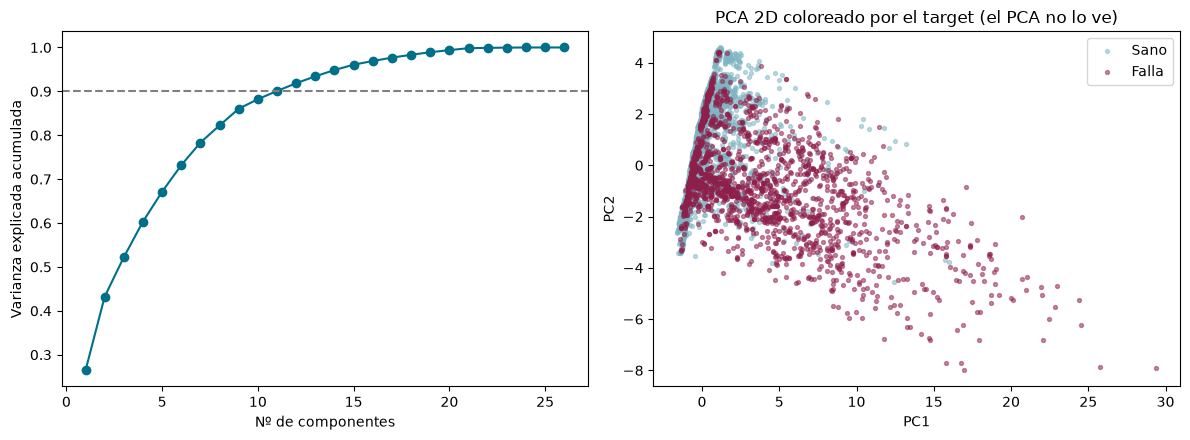

In [12]:
prepro_pca = crear_preprocesado(reducido, escalar = True).fit(X_train)
X_train_esc = prepro_pca.transform(X_train)
pca = PCA(random_state = 42).fit(X_train_esc)
acumulada = np.cumsum(pca.explained_variance_ratio_)
print("Componentes para el 90 % de la varianza:", np.argmax(acumulada >= 0.9) + 1)

X_2d = PCA(n_components = 2, random_state = 42).fit_transform(X_train_esc)
fig, ejes = plt.subplots(1, 2, figsize = (12, 4.5))
ejes[0].plot(range(1, len(acumulada) + 1), acumulada, marker = "o", color = "#00708A")
ejes[0].axhline(0.9, color = "grey", linestyle = "--")
ejes[0].set_xlabel("Nº de componentes")
ejes[0].set_ylabel("Varianza explicada acumulada")
for clase in [0, 1]:
    ejes[1].scatter(X_2d[y_train == clase, 0], X_2d[y_train == clase, 1], s = 8, alpha = 0.5,
                    color = ["#7FB5C3", "#8E1F4B"][clase], label = ["Sano", "Falla"][clase])
ejes[1].set_xlabel("PC1")
ejes[1].set_ylabel("PC2")
ejes[1].legend()
ejes[1].set_title("PCA 2D coloreado por el target (el PCA no lo ve)")
plt.tight_layout()

*Antes del PCA, el fabricante y el datacenter pasan a One-Hot, así que trabaja con 26 columnas: 15 numéricas, 5 de fabricante y 6 de datacenter. Con 11 componentes explico el 90 % de la varianza: se puede comprimir algo, pero no mucho. En el gráfico 2D, los discos que fallan (granate) se concentran hacia una zona aunque el PCA no sabía cuáles eran: la información para separarlos está en los datos. Aun así, en la comparativa PCA + Random Forest quedó en 0,693, por debajo del Random Forest directo, así que comprimir no ayuda.*

## No supervisado (II): KMeans

*Agrupo los discos con KMeans, también sin el target, y pruebo de 2 a 7 grupos. La silueta indica cómo de separados quedan, pero no lo decide todo: luego miro qué hay dentro de cada grupo.*

In [13]:
siluetas = {}
for k in range(2, 8):
    km = KMeans(n_clusters = k, n_init = 10, random_state = 42).fit(X_train_esc)
    siluetas[k] = silhouette_score(X_train_esc, km.labels_, sample_size = 2000, random_state = 42)
print("Silueta por k:", {k: round(v, 3) for k, v in siluetas.items()})

km = KMeans(n_clusters = 4, n_init = 10, random_state = 42).fit(X_train_esc)
resumen = train_set.assign(cluster = km.labels_).groupby("cluster").agg(
    discos = (target, "size"), pct_fallos = (target, "mean"), sectores_pendientes = ("smart_197_raw", "median"))
resumen["pct_fallos"] = (resumen["pct_fallos"] * 100).round(1)
resumen

Silueta por k: {2: 0.626, 3: 0.275, 4: 0.204, 5: 0.195, 6: 0.263, 7: 0.214}


,discos,pct_fallos,sectores_pendientes
cluster,,,
0,4713,6.6,0.0
1,6043,6.1,0.0
2,9218,8.7,0.0
3,786,91.2,261.0


*La silueta más alta es k = 2, pero la silueta premia los grupos redondos y bien separados, y eso no siempre significa grupos útiles. Me quedo con k = 4 porque se pueden interpretar: tres grupos de discos sanos (6-9 % de fallos) y uno de 786 discos con muchos sectores pendientes (mediana 261) en el que falla el 91 %. KMeans encuentra el deterioro sin ver el target, lo mismo que ha aprendido el modelo supervisado.*

## Elegir los umbrales de decisión

*El modelo no dice "falla / no falla", sino una probabilidad. Decido yo a partir de qué valor avisar, y lo hago con predicciones de validación cruzada para no tocar el test. Uso dos umbrales con una regla de negocio escrita en el código:*

- *Vigilar: el umbral más alto que todavía detecta al menos el 70 % de los fallos.*
- *Sustituir: el umbral más bajo con al menos un 85 % de alarmas reales, porque cambiar un disco cuesta dinero y no quiero hacerlo por falsas alarmas.*

In [14]:
modelo_final = grid.best_estimator_
proba_cv = cross_val_predict(modelo_final, X_train, y_train, groups = grupos, cv = cv, method = "predict_proba")[:, 1]
filas = []
for u in np.round(np.arange(0.1, 0.95, 0.05), 2):
    pred = (proba_cv >= u).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_train, pred).ravel()
    filas.append([u, tp / (tp + fn), tp / (tp + fp), fp / (fp + tn) * 1000])
umbrales = pd.DataFrame(filas, columns = ["umbral", "recall", "precision", "falsas_alarmas_por_1000"])

# Vigilar: el umbral más alto que todavía detecta al menos el 70 % de los fallos
# Sustituir: el umbral más bajo con al menos un 85 % de alarmas reales
UMBRAL_VIGILAR = umbrales.loc[umbrales["recall"] >= 0.70, "umbral"].max()
UMBRAL_SUSTITUIR = umbrales.loc[umbrales["precision"] >= 0.85, "umbral"].min()
print("Umbral vigilar:", UMBRAL_VIGILAR, "| umbral sustituir:", UMBRAL_SUSTITUIR)
umbrales.round(3)

Umbral vigilar: 0.2 | umbral sustituir: 0.55


,umbral,recall,precision,falsas_alarmas_por_1000
0,0.10,0.744,0.548,72.683
1,0.15,0.724,0.611,54.634
2,0.20,0.712,0.658,43.966
3,0.25,0.685,0.686,37.069
4,0.30,0.659,0.709,32.004
5,0.35,0.631,0.740,26.239
6,0.40,0.593,0.773,20.636
7,0.45,0.555,0.794,17.080
8,0.50,0.526,0.823,13.416
9,0.55,0.495,0.852,10.237


*Salen 0,20 para vigilar y 0,55 para sustituir, y con ellos monto el semáforo:*

- *🔴 Sustituir (probabilidad ≥ 0,55): el 85 % de estas alarmas son fallos reales.*
- *🟠 Vigilar (entre 0,20 y 0,55): junto con los rojos, detecta el 71 % de los fallos.*
- *🟢 OK (menos de 0,20).*

*Comparado con la regla del técnico (66 % de recall y 57 % de precisión), el umbral de vigilar gana en las dos cosas: detecta más fallos (71 %) con más avisos acertados (66 %). Cuanto más alto el umbral, menos falsas alarmas pero más fallos se escapan; por eso uso dos niveles en lugar de uno.*

## Evaluación en test

*Con todo decidido (modelo, variables, hiperparámetros y umbrales), evalúo una sola vez en test: 5.163 filas de discos que el modelo no ha visto nunca. No cambio nada después de ver este resultado.*

              precision    recall  f1-score   support

           0      0.966     0.954     0.960      4631
           1      0.637     0.705     0.669       532

    accuracy                          0.928      5163
   macro avg      0.801     0.829     0.814      5163
weighted avg      0.932     0.928     0.930      5163

PR-AUC en test: 0.725


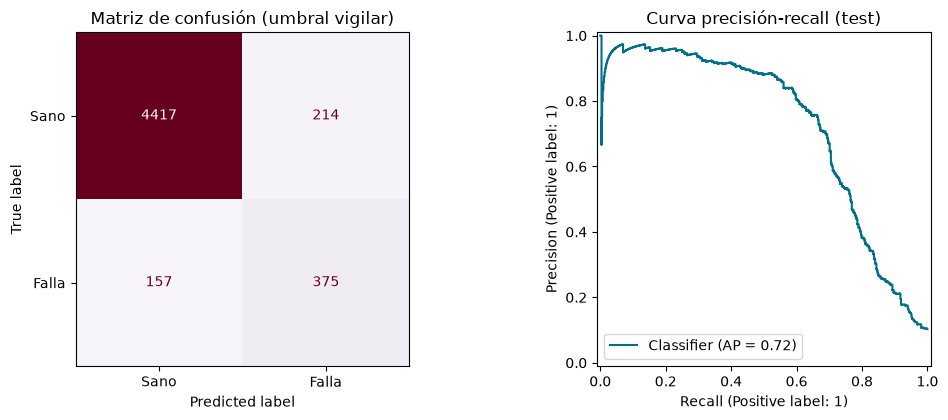

In [15]:
proba_test = modelo_final.predict_proba(X_test)[:, 1]
print(classification_report(y_test, (proba_test >= UMBRAL_VIGILAR).astype(int), digits = 3))
print("PR-AUC en test:", round(average_precision_score(y_test, proba_test), 3))

fig, ejes = plt.subplots(1, 2, figsize = (11, 4.3))
ConfusionMatrixDisplay.from_predictions(y_test, (proba_test >= UMBRAL_VIGILAR).astype(int), cmap = "PuRd",
                                        display_labels = ["Sano", "Falla"], ax = ejes[0], colorbar = False)
ejes[0].set_title("Matriz de confusión (umbral vigilar)")

PrecisionRecallDisplay.from_predictions(y_test, proba_test, ax = ejes[1], curve_kwargs = {"color": "#00708A"})
ejes[1].set_title("Curva precisión-recall (test)")
plt.tight_layout()

*En test, la PR-AUC es 0,725, la misma que en validación cruzada (0,725): no hay sobreajuste a train y la validación agrupada estimaba bien. Con el umbral de vigilar detecto 375 de los 532 fallos (70,5 %). A cambio, 214 de los 4.631 discos sanos dan una alarma de vigilancia: 46 por cada 1.000.*

## ¿Cuánto me puedo fiar de estas cifras? Intervalos bootstrap

*Remuestreo el test 1.000 veces con reemplazo y recalculo recall y precisión cada vez. El intervalo del 95 % dice entre qué valores se movería el resultado con otra muestra de discos parecida.*

In [16]:
def intervalo_bootstrap(y_real, y_pred, funcion, n = 1000):
    rng = np.random.default_rng(42)
    y_real = np.array(y_real)
    y_pred = np.array(y_pred)
    valores = []
    for i in range(n):
        idx = rng.integers(0, len(y_real), len(y_real))
        valores.append(funcion(y_real[idx], y_pred[idx]))
    return np.percentile(valores, 2.5), np.percentile(valores, 97.5)

for nombre, u in [("vigilar", UMBRAL_VIGILAR), ("sustituir", UMBRAL_SUSTITUIR)]:
    pred = (proba_test >= u).astype(int)
    ic_r = intervalo_bootstrap(y_test, pred, recall_score)
    ic_p = intervalo_bootstrap(y_test, pred, precision_score)
    print(nombre, "| recall", round(recall_score(y_test, pred), 3), "IC95", np.round(ic_r, 3),
          "| precisión", round(precision_score(y_test, pred), 3), "IC95", np.round(ic_p, 3))

vigilar | recall 0.705 IC95 [0.666 0.741] | precisión 0.637 IC95 [0.598 0.677]
sustituir | recall 0.549 IC95 [0.507 0.588] | precisión 0.864 IC95 [0.823 0.9  ]


*Con el umbral de vigilar detecto el 71 % de los fallos, con un intervalo del 67 al 74 %. Con el de sustituir, el 86 % de las alarmas son fallos reales (entre el 82 y el 90 %). Incluso en el peor extremo de los intervalos, el modelo sigue por encima de la regla del técnico (66 % de recall y 57 % de precisión).*

## ¿En qué se fija el modelo? Permutation importance

*Desordeno cada variable en test, una a una, y mido cuánto empeora la PR-AUC. Si al desordenarla el modelo pierde mucho, es que dependía de ella. Lo repito 10 veces para tener una media y su variación.*

,variable,media,std
5,smart_197_raw,0.118,0.008
8,delta_5,0.043,0.004
1,smart_5_raw,0.039,0.003
0,smart_1_raw,0.025,0.004
13,capacidad_tb,0.023,0.003
15,fabricante,0.022,0.005
6,smart_198_raw,0.021,0.003
4,smart_193_raw,0.016,0.003


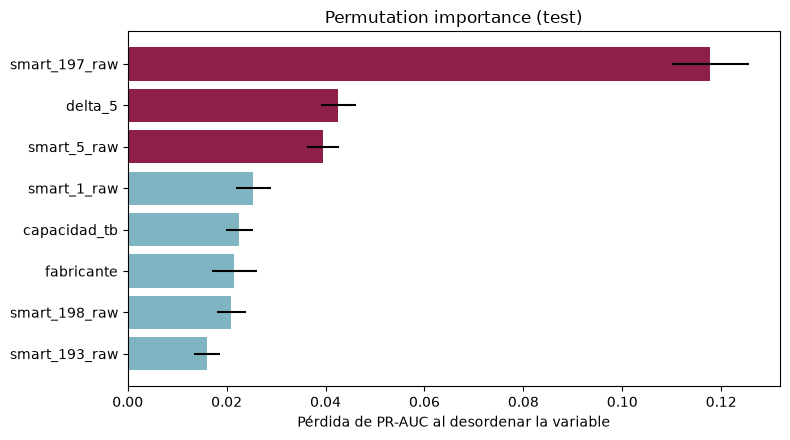

In [17]:
imp = permutation_importance(modelo_final, X_test, y_test, scoring = "average_precision", n_repeats = 10, random_state = 42)
importancias = pd.DataFrame({"variable": X_test.columns, "media": imp.importances_mean, "std": imp.importances_std})
importancias = importancias.sort_values("media").tail(8)
plt.figure(figsize = (8, 4.5))
plt.barh(importancias["variable"], importancias["media"], xerr = importancias["std"],
         color = ["#8E1F4B" if v >= importancias["media"].iloc[-3] else "#7FB5C3" for v in importancias["media"]])
plt.xlabel("Pérdida de PR-AUC al desordenar la variable")
plt.title("Permutation importance (test)")
plt.tight_layout()
importancias.sort_values("media", ascending = False).round(3)

*Lo que más pesa con diferencia son los sectores pendientes (smart_197): al desordenarlos, la PR-AUC cae 0,12. Les siguen cuánto han subido los sectores reasignados en el último mes (delta_5) y su valor actual (smart_5). Tiene sentido físico: la superficie del disco se va dañando antes de que falle, y que el daño crezca es tan importante como cuánto hay. Una variable importante no es una causa: el modelo la usa porque acompaña al fallo, no porque lo provoque.*

## ¿Qué fallos se le escapan?

*Miro los fallos que el modelo no detecta con el umbral de vigilar. Quiero saber si son errores del modelo o fallos que no se podían ver con estos datos.*

In [18]:
pred = (proba_test >= UMBRAL_VIGILAR).astype(int)
errores = test_set.assign(proba = proba_test, pred = pred)
sin_senal = (errores[["smart_5_raw", "smart_197_raw", "smart_198_raw"]].fillna(0) == 0).all(axis = 1)
fn = errores[(errores[target] == 1) & (errores["pred"] == 0)]
tp = errores[(errores[target] == 1) & (errores["pred"] == 1)]
print("Fallos no detectados sin ninguna señal SMART:", round(sin_senal[fn.index].mean() * 100), "%")
print("Fallos detectados sin ninguna señal SMART:", round(sin_senal[tp.index].mean() * 100), "%")
fallan = errores[errores[target] == 1]
fallan.groupby("fabricante")["pred"].agg(fallos = "size", recall = "mean").round(2)

Fallos no detectados sin ninguna señal SMART: 89 %
Fallos detectados sin ninguna señal SMART: 9 %


,fallos,recall
fabricante,,
HGST,90,0.91
Otros,6,0.17
Seagate,203,0.69
TOSHIBA,158,0.62
WDC,75,0.72


*El 89 % de los fallos que se escapan no tenía ninguna señal en los contadores de sectores: el disco murió de golpe, sin avisar. Ningún modelo con estos datos puede verlos; para eso están el RAID y las copias de seguridad. Por fabricante, acierta más en HGST (91 %) y menos en Toshiba (62 %). En "Otros" solo hay 6 fallos, demasiado pocos para sacar conclusiones.*

## Prueba final: abril de 2026

*Abril es un mes posterior a todo lo que ha visto el modelo y con discos que no aparecen en enero ni en febrero. Es lo más parecido a ponerlo en producción: si aquí funciona, generaliza al futuro.*

In [19]:
abril = pd.read_csv("data/test/test_abril.csv", low_memory = False)
proba_abril = modelo_final.predict_proba(abril[variables + features_cat])[:, 1]
print("Abril |", len(abril), "discos |", abril[target].sum(), "fallos")
print("Recall (vigilar):", round(recall_score(abril[target], proba_abril >= UMBRAL_VIGILAR), 3))
print("Precisión (sustituir):", round(precision_score(abril[target], proba_abril >= UMBRAL_SUSTITUIR), 3))

Abril | 4402 discos | 467 fallos
Recall (vigilar): 0.758
Precisión (sustituir): 0.858


*En abril detecta el 76 % de los fallos con el umbral de vigilar, y el 86 % de las alarmas de sustituir son reales. Es incluso algo mejor que en test (71 % y 86 %), así que el modelo no se ha quedado anclado a enero y febrero: generaliza a un mes que no ha visto.*

## ¿Compensa? Beneficio neto por cada 1.000 discos

*Traduzco el resultado a dinero con el umbral de sustituir. Los costes son supuestos razonables, no datos de Backblaze: un fallo por sorpresa cuesta 5.000 € (recuperar datos, horas de técnico, servicio degradado), un cambio planificado 300 € y una falsa alarma 50 € (revisar un disco sano).*

*Uso la proporción real de fallos de la flota (0,9 por cada 1.000 discos al mes), no la de mi muestra (11 %), que tiene más fallos a propósito para que el modelo aprenda. Como el coste de un fallo varía mucho de una empresa a otra, calculo el beneficio para varios valores.*

In [20]:
PREVALENCIA_REAL = 0.899 / 1000        # fallos en 30 días por disco en la flota real
COSTE_FALLO_SORPRESA = 5000
COSTE_CAMBIO_PLANIFICADO = 300
COSTE_FALSA_ALARMA = 50

def beneficio_por_1000(recall, falsas_por_1000_sanos, coste_sorpresa):
    fallos = 1000 * PREVALENCIA_REAL
    ahorro = fallos * recall * (coste_sorpresa - COSTE_CAMBIO_PLANIFICADO)
    coste = (1000 - fallos) * falsas_por_1000_sanos / 1000 * COSTE_FALSA_ALARMA
    return ahorro - coste

pred = (proba_test >= UMBRAL_SUSTITUIR).astype(int)
tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
r, fa = tp / (tp + fn), fp / (fp + tn) * 1000
pd.DataFrame({"coste_fallo_sorpresa": [1000, 2000, 5000, 10000, 20000],
              "beneficio_neto_mes_por_1000": [round(beneficio_por_1000(r, fa, c)) for c in [1000, 2000, 5000, 10000, 20000]]})

,coste_fallo_sorpresa,beneficio_neto_mes_por_1000
0,1000,-151
1,2000,343
2,5000,1823
3,10000,4290
4,20000,9224


*Con un fallo sorpresa de 5.000 €, el modelo ahorra unos 1.800 € al mes por cada 1.000 discos. Si el fallo costara solo 1.000 €, saldría a pérdidas (−151 €): las falsas alarmas costarían más de lo que se ahorra. Empieza a compensar a partir de unos 1.300 € por fallo, y cuanto más caro es un fallo, más rentable resulta. Por eso guardo los umbrales en un archivo de configuración: cada empresa puede ajustarlos a sus costes sin reentrenar el modelo.*

## Guardar el modelo y lo que necesita la app

*Guardo el pipeline completo (preprocesado y Random Forest) en un pickle, y los umbrales y las variables en un JSON aparte, para poder cambiarlos sin tocar el modelo. Para la app preparo también los valores típicos de cada variable y un CSV de ejemplo con 20 discos de test. Al final cargo el modelo de nuevo para comprobar que se ha guardado bien.*

In [21]:
os.makedirs("models", exist_ok = True)
with open("models/final_model.pkl", "wb") as f:
    pickle.dump(modelo_final, f)
config = {"features_num": variables, "features_cat": features_cat,
          "umbral_vigilar": UMBRAL_VIGILAR, "umbral_sustituir": UMBRAL_SUSTITUIR}
with open("models/config_modelo.json", "w") as f:
    json.dump(config, f, indent = 2)

# Para la app: valores típicos (mediana de train) y un CSV de ejemplo con 20 discos de test
os.makedirs("app_streamlit", exist_ok = True)
tipicos = {"medianas": train_set[variables].median().to_dict(),
           "fabricantes": sorted(train_set["fabricante"].unique()),
           "datacenters": sorted(train_set["datacenter"].unique())}
with open("app_streamlit/valores_tipicos.json", "w") as f:
    json.dump(tipicos, f, indent = 2)
ultima = test_set.drop_duplicates("serial_number", keep = "last")          # una fila por disco: su última fecha
ejemplo = pd.concat([ultima.sort_values("smart_197_raw", ascending = False).head(5), ultima.sample(15, random_state = 42)])
ejemplo.to_csv("app_streamlit/ejemplo_discos.csv", index = False)

with open("models/final_model.pkl", "rb") as f:
    comprobacion = pickle.load(f)
print("Modelo cargado de nuevo. Probabilidad del primer disco de test:", round(comprobacion.predict_proba(X_test.head(1))[0, 1], 3))

Modelo cargado de nuevo. Probabilidad del primer disco de test: 0.974


*El modelo se guarda y se vuelve a cargar sin problemas. Resumen del notebook: Random Forest (300 árboles, profundidad 12, hojas de 5 como mínimo), 15 variables numéricas más fabricante y datacenter, umbrales 0,20 para vigilar y 0,55 para sustituir. En test detecta el 71 % de los fallos con el umbral de vigilar, y el 86 % de las alarmas de sustituir son reales; en abril, el 76 % y el 86 %.*